# Day 053 | Feature Importance & SHAP Explainability

## 100 Days of ML for Geotechnical Engineering
**Phase:** Classical Machine Learning

**Author:** Ripon Chandra Malo  
**Date:** YYYY-MM-DD  

---

## What We Will Learn Today

| Concept | What It Means | Geotechnical Example |
|---------|--------------|---------------------|
| Tree-based Importance | Feature split frequency / impurity reduction | Which soil property dominates bearing capacity? |
| Permutation Importance | Shuffling a feature and measuring accuracy drop | If we scramble N-values, how much worse is prediction? |
| SHAP Values | Shapley additive explanations for each prediction | Why did the model predict high bearing capacity for THIS site? |
| Global vs Local Explanations | Overall trends vs individual predictions | Average drivers vs site-specific reasoning |
| Feature Interaction | How features combine to affect predictions | Cohesion + depth interaction effect |
| Model Transparency | Making black-box models interpretable | Explaining ML predictions to project managers |

---

## Our Geotechnical Problem

We predict **bearing capacity (kPa)** of shallow foundations using soil and geometry features.  
Beyond getting accurate predictions, engineers need to **understand WHY** the model makes certain predictions.  
This is critical for trust, safety review, and regulatory acceptance of ML in practice.

---

## Part 1: Generate Bearing Capacity Data and Train Model

In [1]:
# ─────────────────────────────────────────────────────
# IMPORTS AND DATA GENERATION
# ─────────────────────────────────────────────────────

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings('ignore')

np.random.seed(42)
n = 500

# Features
footing_width = np.random.uniform(1.0, 4.0, n)
footing_depth = np.random.uniform(0.5, 3.0, n)
cohesion = np.random.uniform(0, 80, n)           # kPa
friction_angle = np.random.uniform(5, 40, n)     # degrees
unit_weight = np.random.uniform(16, 21, n)       # kN/m3
N_value = np.random.randint(5, 50, n)
water_table = np.random.uniform(0.5, 8.0, n)

# Bearing capacity (simplified Terzaghi-inspired)
phi_rad = np.radians(friction_angle)
Nq = np.exp(np.pi * np.tan(phi_rad)) * np.tan(np.radians(45) + phi_rad/2)**2
Nc = (Nq - 1) / np.tan(phi_rad + 1e-6)
Ngamma = 2 * (Nq + 1) * np.tan(phi_rad)

qult = (cohesion * Nc +
        unit_weight * footing_depth * Nq +
        0.5 * unit_weight * footing_width * Ngamma)
qult += np.random.normal(0, qult * 0.05)  # 5% noise
qult = np.clip(qult, 50, 10000)

df = pd.DataFrame({
    'footing_width': footing_width,
    'footing_depth': footing_depth,
    'cohesion': cohesion,
    'friction_angle': friction_angle,
    'unit_weight': unit_weight,
    'N_value': N_value,
    'water_table': water_table,
    'bearing_capacity': qult
})

print(f"Dataset shape: {df.shape}")
print(f"\nBearing capacity range: {qult.min():.0f} - {qult.max():.0f} kPa")
print(df.describe().round(2))

Dataset shape: (500, 8)

Bearing capacity range: 54 - 10000 kPa
       footing_width  footing_depth  cohesion  friction_angle  unit_weight  \
count         500.00         500.00    500.00          500.00       500.00   
mean            2.50           1.70     41.40           22.38        18.50   
std             0.90           0.71     23.78           10.05         1.43   
min             1.02           0.51      0.40            5.11        16.01   
25%             1.72           1.07     19.30           13.44        17.34   
50%             2.54           1.68     43.18           22.81        18.48   
75%             3.27           2.32     62.19           30.81        19.72   
max             3.98           3.00     79.95           39.94        20.98   

       N_value  water_table  bearing_capacity  
count   500.00       500.00            500.00  
mean     27.47         4.24           1894.28  
std      12.87         2.13           1983.55  
min       5.00         0.50             5

In [2]:
# ─────────────────────────────────────────────────────
# TRAIN RANDOM FOREST MODEL
# ─────────────────────────────────────────────────────

from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.metrics import r2_score, mean_squared_error

features = ['footing_width', 'footing_depth', 'cohesion',
            'friction_angle', 'unit_weight', 'N_value', 'water_table']
X = df[features]
y = df['bearing_capacity']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

rf = RandomForestRegressor(n_estimators=300, max_depth=12, random_state=42)
rf.fit(X_train, y_train)
y_pred = rf.predict(X_test)

print(f"Random Forest Performance:")
print(f"  R2   = {r2_score(y_test, y_pred):.4f}")
print(f"  RMSE = {np.sqrt(mean_squared_error(y_test, y_pred)):.1f} kPa")

Random Forest Performance:
  R2   = 0.9558
  RMSE = 382.1 kPa


---

## Part 2: Tree-Based Feature Importance (MDI)

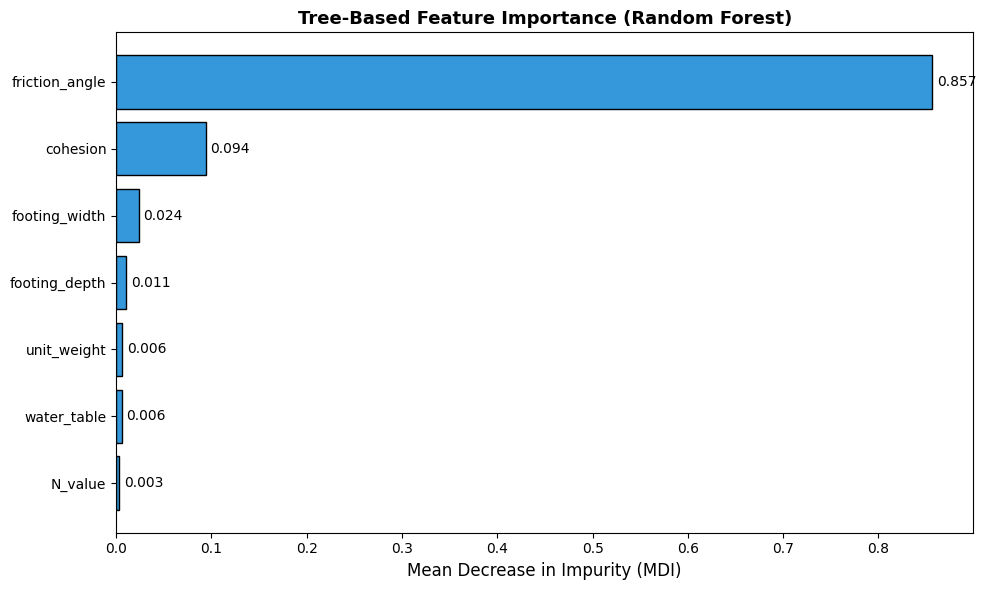

MDI importance: how much each feature reduces prediction error in tree splits.
Caveat: MDI is biased towards high-cardinality features (many unique values).


In [3]:
# ─────────────────────────────────────────────────────
# TREE-BASED (MDI) FEATURE IMPORTANCE
# ─────────────────────────────────────────────────────

importances_mdi = rf.feature_importances_
sorted_idx = np.argsort(importances_mdi)

fig, ax = plt.subplots(figsize=(10, 6))
ax.barh(np.array(features)[sorted_idx], importances_mdi[sorted_idx],
        color='#3498db', edgecolor='black')
ax.set_xlabel('Mean Decrease in Impurity (MDI)', fontsize=12)
ax.set_title('Tree-Based Feature Importance (Random Forest)', fontsize=13, fontweight='bold')

for i, (val, name) in enumerate(zip(importances_mdi[sorted_idx], np.array(features)[sorted_idx])):
    ax.text(val + 0.005, i, f'{val:.3f}', va='center', fontsize=10)

plt.tight_layout()
plt.show()

print("MDI importance: how much each feature reduces prediction error in tree splits.")
print("Caveat: MDI is biased towards high-cardinality features (many unique values).")

---

## Part 3: Permutation Importance

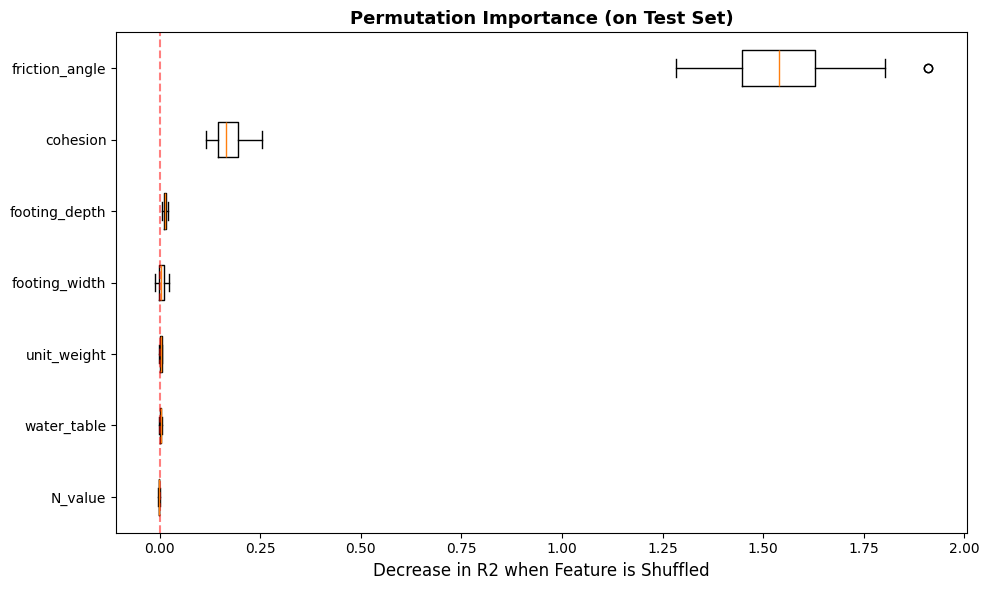

Permutation importance: shuffle one feature, measure performance drop.
More reliable than MDI — not biased by cardinality.
Features near zero or negative have little predictive value.


In [4]:
# ─────────────────────────────────────────────────────
# PERMUTATION IMPORTANCE — Model-agnostic
# ─────────────────────────────────────────────────────

from sklearn.inspection import permutation_importance

perm_result = permutation_importance(
    rf, X_test, y_test, n_repeats=30, random_state=42, scoring='r2'
)

perm_sorted = perm_result.importances_mean.argsort()

fig, ax = plt.subplots(figsize=(10, 6))
ax.boxplot(
    perm_result.importances[perm_sorted].T,
    vert=False,
    labels=np.array(features)[perm_sorted]
)
ax.set_xlabel('Decrease in R2 when Feature is Shuffled', fontsize=12)
ax.set_title('Permutation Importance (on Test Set)', fontsize=13, fontweight='bold')
ax.axvline(x=0, color='red', linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

print("Permutation importance: shuffle one feature, measure performance drop.")
print("More reliable than MDI — not biased by cardinality.")
print("Features near zero or negative have little predictive value.")

---

## Part 4: Comparing MDI vs Permutation Importance

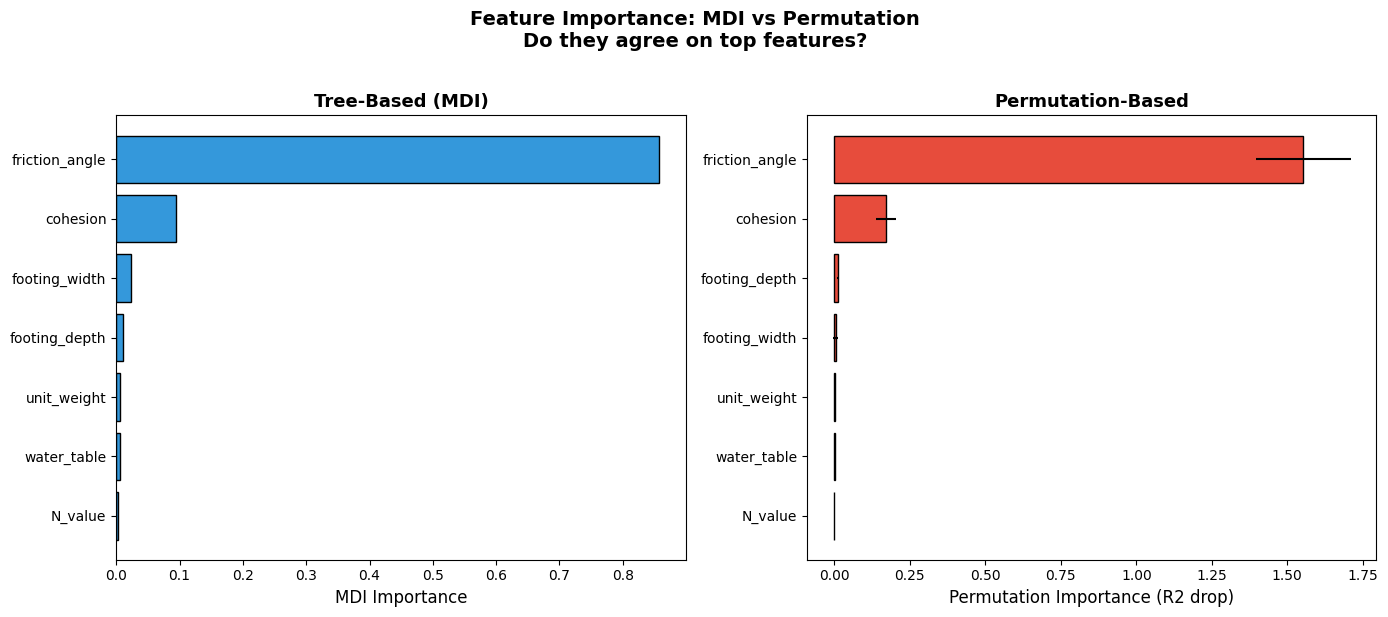


Feature Ranking Comparison:
Rank   MDI                  Permutation         
----------------------------------------------
1      friction_angle       friction_angle      
2      cohesion             cohesion            
3      footing_width        footing_depth       
4      footing_depth        footing_width       
5      unit_weight          unit_weight         
6      water_table          water_table         
7      N_value              N_value             


In [5]:
# ─────────────────────────────────────────────────────
# MDI vs PERMUTATION — Side by side comparison
# ─────────────────────────────────────────────────────

fig, axes = plt.subplots(1, 2, figsize=(14, 6))

# MDI
axes[0].barh(np.array(features)[sorted_idx], importances_mdi[sorted_idx],
             color='#3498db', edgecolor='black')
axes[0].set_xlabel('MDI Importance', fontsize=12)
axes[0].set_title('Tree-Based (MDI)', fontsize=13, fontweight='bold')

# Permutation
axes[1].barh(np.array(features)[perm_sorted], perm_result.importances_mean[perm_sorted],
             color='#e74c3c', edgecolor='black',
             xerr=perm_result.importances_std[perm_sorted])
axes[1].set_xlabel('Permutation Importance (R2 drop)', fontsize=12)
axes[1].set_title('Permutation-Based', fontsize=13, fontweight='bold')

plt.suptitle('Feature Importance: MDI vs Permutation\nDo they agree on top features?',
             fontsize=14, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

# Print ranking comparison
mdi_rank = np.array(features)[np.argsort(-importances_mdi)]
perm_rank = np.array(features)[np.argsort(-perm_result.importances_mean)]
print("\nFeature Ranking Comparison:")
print(f"{'Rank':<6} {'MDI':<20} {'Permutation':<20}")
print("-" * 46)
for i in range(len(features)):
    print(f"{i+1:<6} {mdi_rank[i]:<20} {perm_rank[i]:<20}")

---

## Part 5: SHAP Concepts — Manual Computation

In [6]:
# ─────────────────────────────────────────────────────
# SHAP CONCEPTS — Compute manually with TreeExplainer or fallback
# ─────────────────────────────────────────────────────

try:
    import shap
    has_shap = True
    print("SHAP library found! Using TreeExplainer.")
except ImportError:
    has_shap = False
    print("SHAP not installed. Computing approximate SHAP values manually.")
    print("Install with: pip install shap")

if has_shap:
    explainer = shap.TreeExplainer(rf)
    shap_values = explainer.shap_values(X_test)
    print(f"\nSHAP values shape: {shap_values.shape}")
    print(f"Each sample gets {shap_values.shape[1]} SHAP values (one per feature)")
else:
    # Manual approximate SHAP: use permutation-based marginal contributions
    print("\nComputing approximate SHAP via marginal contributions...")
    n_samples_explain = min(50, len(X_test))
    X_explain = X_test.iloc[:n_samples_explain]
    base_pred = rf.predict(X_explain)
    baseline = y_train.mean()
    
    shap_values = np.zeros((n_samples_explain, len(features)))
    for j, feat in enumerate(features):
        X_shuffled = X_explain.copy()
        # Replace feature with random values from training set
        X_shuffled[feat] = np.random.choice(X_train[feat].values, n_samples_explain)
        pred_without = rf.predict(X_shuffled)
        shap_values[:, j] = base_pred - pred_without
    
    print(f"Approximate SHAP values computed for {n_samples_explain} samples.")

SHAP library found! Using TreeExplainer.



SHAP values shape: (100, 7)
Each sample gets 7 SHAP values (one per feature)


---

## Part 6: SHAP Summary Plot (Global Explanation)

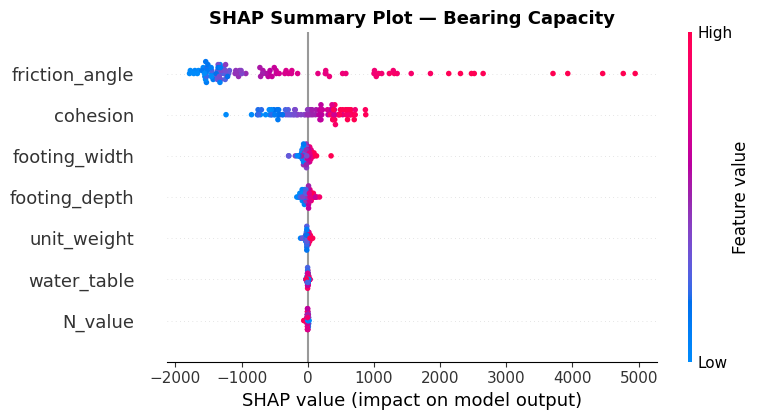


SHAP values show BOTH importance AND direction:
  Positive SHAP = pushes prediction UP
  Negative SHAP = pushes prediction DOWN


In [7]:
# ─────────────────────────────────────────────────────
# SHAP SUMMARY PLOT — Global feature importance with direction
# ─────────────────────────────────────────────────────

if has_shap:
    plt.figure(figsize=(10, 6))
    shap.summary_plot(shap_values, X_test, feature_names=features, show=False)
    plt.title('SHAP Summary Plot — Bearing Capacity', fontsize=13, fontweight='bold')
    plt.tight_layout()
    plt.show()
else:
    # Manual SHAP-like summary plot
    mean_abs_shap = np.abs(shap_values).mean(axis=0)
    sorted_idx_shap = np.argsort(mean_abs_shap)
    
    fig, axes = plt.subplots(1, 2, figsize=(14, 6))
    
    # Bar plot of mean |SHAP|
    axes[0].barh(np.array(features)[sorted_idx_shap], mean_abs_shap[sorted_idx_shap],
                 color='#9b59b6', edgecolor='black')
    axes[0].set_xlabel('Mean |SHAP Value| (kPa)', fontsize=12)
    axes[0].set_title('Global Feature Importance (SHAP)', fontsize=13, fontweight='bold')
    
    # Dot plot showing direction
    top_feat_idx = sorted_idx_shap[-1]  # most important feature
    top_feat = features[top_feat_idx]
    X_plot = X_explain if not has_shap else X_test
    sc = axes[1].scatter(shap_values[:, top_feat_idx], range(len(shap_values)),
                          c=X_plot[top_feat].values[:len(shap_values)],
                          cmap='RdYlBu_r', s=20, alpha=0.7)
    axes[1].set_xlabel(f'SHAP Value for {top_feat}', fontsize=12)
    axes[1].set_ylabel('Sample Index', fontsize=12)
    axes[1].set_title(f'SHAP Values vs Feature Value ({top_feat})', fontsize=13, fontweight='bold')
    axes[1].axvline(x=0, color='black', linestyle='--', alpha=0.3)
    plt.colorbar(sc, ax=axes[1], label=top_feat)
    
    plt.tight_layout()
    plt.show()

print("\nSHAP values show BOTH importance AND direction:")
print("  Positive SHAP = pushes prediction UP")
print("  Negative SHAP = pushes prediction DOWN")

---

## Part 7: SHAP for Individual Predictions (Local Explanation)

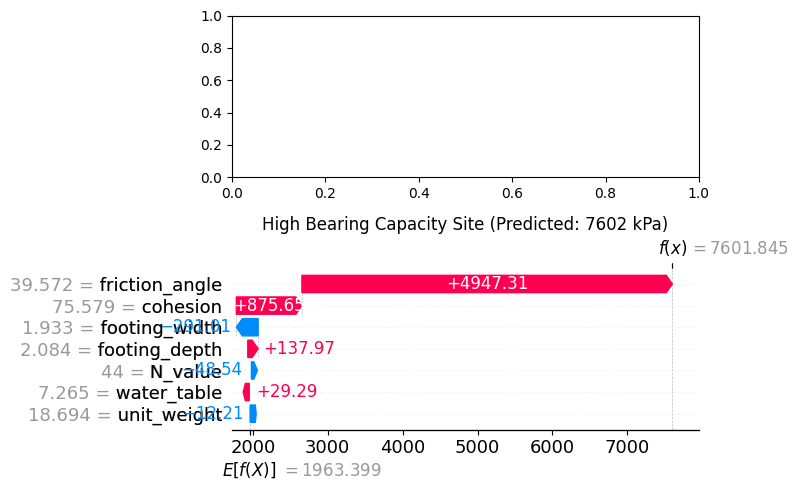

Red bars = feature pushes prediction HIGHER
Blue bars = feature pushes prediction LOWER

This is how you explain individual ML predictions to engineers.


In [8]:
# ─────────────────────────────────────────────────────
# LOCAL EXPLANATION — Why did the model predict THIS value?
# ─────────────────────────────────────────────────────

# Pick two contrasting samples
high_idx = y_test.idxmax()
low_idx = y_test.idxmin()

high_pos = list(X_test.index).index(high_idx)
low_pos = list(X_test.index).index(low_idx)

if has_shap:
    fig, axes = plt.subplots(2, 1, figsize=(12, 8))
    shap.plots.waterfall(shap.Explanation(
        values=shap_values[high_pos], base_values=explainer.expected_value,
        data=X_test.iloc[high_pos], feature_names=features), show=False)
    plt.title(f'High Bearing Capacity Site (Predicted: {rf.predict(X_test.iloc[[high_pos]])[0]:.0f} kPa)')
    plt.tight_layout()
    plt.show()
else:
    # Manual waterfall-style explanation
    fig, axes = plt.subplots(1, 2, figsize=(14, 6))
    
    for ax_idx, (pos, title) in enumerate([(min(high_pos, len(shap_values)-1), 'High Capacity'),
                                            (min(low_pos, len(shap_values)-1), 'Low Capacity')]):
        sv = shap_values[pos]
        sort_order = np.argsort(np.abs(sv))
        colors = ['#e74c3c' if v > 0 else '#3498db' for v in sv[sort_order]]
        
        axes[ax_idx].barh(np.array(features)[sort_order], sv[sort_order],
                          color=colors, edgecolor='black')
        axes[ax_idx].set_xlabel('SHAP Value (contribution to prediction)', fontsize=11)
        axes[ax_idx].set_title(f'{title} Site', fontsize=13, fontweight='bold')
        axes[ax_idx].axvline(x=0, color='black', linestyle='-', alpha=0.3)
    
    plt.suptitle('Local Explanations: What Drives Each Prediction?',
                 fontsize=14, fontweight='bold', y=1.02)
    plt.tight_layout()
    plt.show()

print("Red bars = feature pushes prediction HIGHER")
print("Blue bars = feature pushes prediction LOWER")
print("\nThis is how you explain individual ML predictions to engineers.")

---

## Part 8: Feature Dependence — How Features Affect Predictions

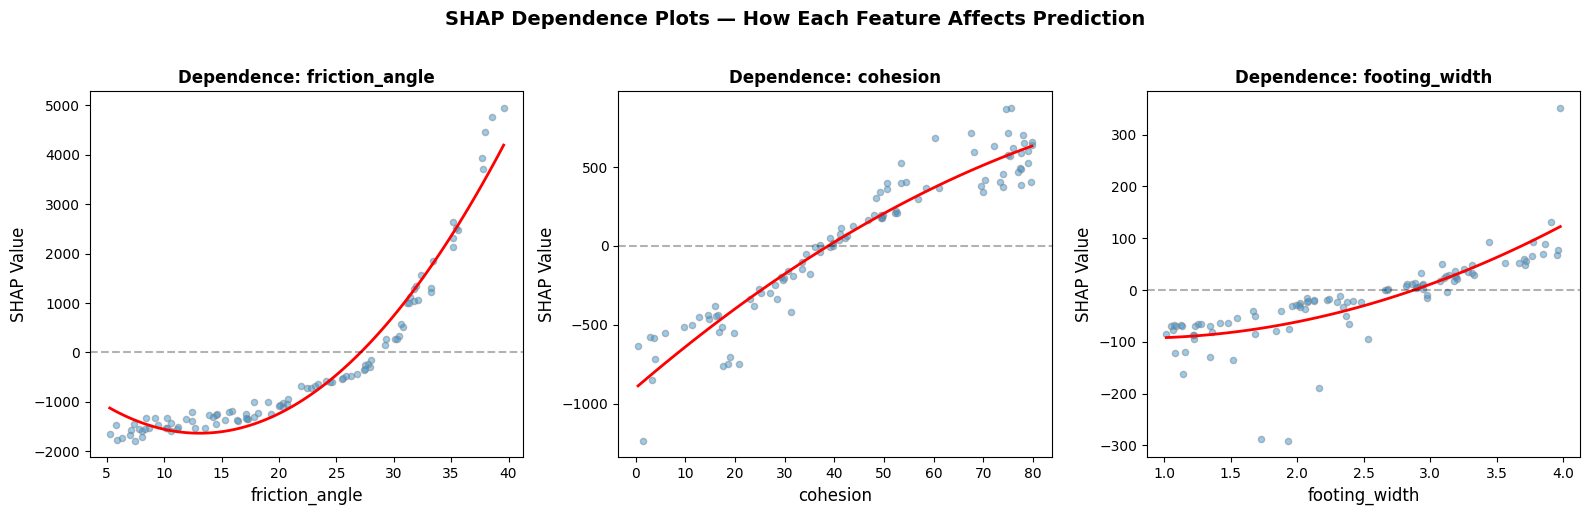

These plots show the NONLINEAR relationship each feature has with the prediction.
Unlike linear regression coefficients, SHAP captures complex interactions.


In [9]:
# ─────────────────────────────────────────────────────
# PARTIAL DEPENDENCE / SHAP DEPENDENCE PLOTS
# ─────────────────────────────────────────────────────

top_3_features = np.array(features)[np.argsort(-np.abs(shap_values).mean(axis=0))[:3]]

fig, axes = plt.subplots(1, 3, figsize=(16, 5))

X_plot_data = X_explain if not has_shap else X_test
for i, feat in enumerate(top_3_features):
    feat_idx = features.index(feat)
    feat_vals = X_plot_data[feat].values[:len(shap_values)]
    shap_vals = shap_values[:, feat_idx]
    
    axes[i].scatter(feat_vals, shap_vals, alpha=0.5, s=20, color='#3498db', edgecolors='gray')
    # Add trend line
    z = np.polyfit(feat_vals, shap_vals, 2)
    x_smooth = np.linspace(feat_vals.min(), feat_vals.max(), 100)
    axes[i].plot(x_smooth, np.polyval(z, x_smooth), 'r-', linewidth=2)
    axes[i].axhline(y=0, color='black', linestyle='--', alpha=0.3)
    axes[i].set_xlabel(feat, fontsize=12)
    axes[i].set_ylabel('SHAP Value', fontsize=12)
    axes[i].set_title(f'Dependence: {feat}', fontsize=12, fontweight='bold')

plt.suptitle('SHAP Dependence Plots — How Each Feature Affects Prediction',
             fontsize=14, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

print("These plots show the NONLINEAR relationship each feature has with the prediction.")
print("Unlike linear regression coefficients, SHAP captures complex interactions.")

---

## Part 9: Comparing Importance Across Models

Normalized Feature Importance Comparison:
                RF (MDI)  RF (Permutation)  GB (MDI)  GB (Permutation)  \
footing_width      0.024             0.002     0.027            -0.001   
footing_depth      0.011             0.007     0.010             0.012   
cohesion           0.094             0.098     0.108             0.101   
friction_angle     0.857             0.891     0.850             0.883   
unit_weight        0.006             0.002     0.004             0.002   
N_value            0.003            -0.001     0.001            -0.000   
water_table        0.006             0.001     0.001             0.003   

                SHAP (mean |value|)  
footing_width                 0.031  
footing_depth                 0.028  
cohesion                      0.212  
friction_angle                0.710  
unit_weight                   0.011  
N_value                       0.004  
water_table                   0.004  



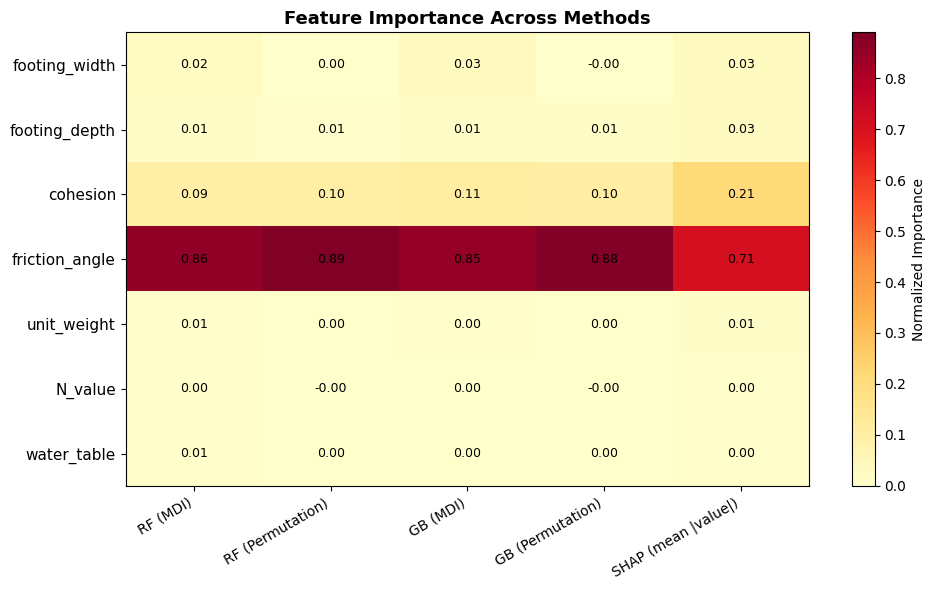

Features that are important across ALL methods are truly important.
Disagreements may indicate feature interactions or collinearity.


In [10]:
# ─────────────────────────────────────────────────────
# COMPARE IMPORTANCE METHODS ACROSS MODELS
# ─────────────────────────────────────────────────────

gb = GradientBoostingRegressor(n_estimators=300, max_depth=5, random_state=42)
gb.fit(X_train, y_train)

# Permutation importance for GB
perm_gb = permutation_importance(gb, X_test, y_test, n_repeats=20, random_state=42)

# Compare all methods
comparison = pd.DataFrame({
    'RF (MDI)': rf.feature_importances_,
    'RF (Permutation)': perm_result.importances_mean,
    'GB (MDI)': gb.feature_importances_,
    'GB (Permutation)': perm_gb.importances_mean,
    'SHAP (mean |value|)': np.abs(shap_values).mean(axis=0)
}, index=features)

# Normalize each column to sum to 1 for comparison
comparison_norm = comparison.div(comparison.sum(axis=0), axis=1)

print("Normalized Feature Importance Comparison:")
print("=" * 70)
print(comparison_norm.round(3))
print()

# Heatmap
fig, ax = plt.subplots(figsize=(10, 6))
im = ax.imshow(comparison_norm.values, cmap='YlOrRd', aspect='auto')
ax.set_xticks(range(len(comparison_norm.columns)))
ax.set_xticklabels(comparison_norm.columns, rotation=30, ha='right', fontsize=10)
ax.set_yticks(range(len(features)))
ax.set_yticklabels(features, fontsize=11)

for i in range(len(features)):
    for j in range(len(comparison_norm.columns)):
        ax.text(j, i, f'{comparison_norm.values[i,j]:.2f}',
                ha='center', va='center', fontsize=9)

plt.colorbar(im, label='Normalized Importance')
ax.set_title('Feature Importance Across Methods', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()

print("Features that are important across ALL methods are truly important.")
print("Disagreements may indicate feature interactions or collinearity.")

---

## Practice Exercises

### Exercise 1: Drop Unimportant Features
Remove the 2 least important features according to SHAP. Retrain and compare R2. Is the simpler model nearly as good?

### Exercise 2: SHAP for a New Sample
Create a synthetic site: B=2m, Df=1.5m, c=50kPa, phi=30deg, gamma=19kN/m3, N=25, WT=3m. Compute SHAP values and explain the prediction.

### Exercise 3: Compare SHAP for RF vs GB
Compute SHAP values for the GradientBoosting model. Do the two models agree on which features matter most?

In [11]:
# EXERCISE 1 STARTER:
# bottom_2 = np.array(features)[np.argsort(np.abs(shap_values).mean(axis=0))[:2]]
# print(f"Dropping: {bottom_2}")
# features_reduced = [f for f in features if f not in bottom_2]
# rf_small = RandomForestRegressor(n_estimators=300, max_depth=12, random_state=42)
# rf_small.fit(X_train[features_reduced], y_train)
# y_pred_small = rf_small.predict(X_test[features_reduced])
# print(f"Full model R2:    {r2_score(y_test, y_pred):.4f}")
# print(f"Reduced model R2: {r2_score(y_test, y_pred_small):.4f}")

---

## Key Takeaways

1. **Tree-based (MDI) importance** is fast but biased toward high-cardinality features. Use as a quick first look only.

2. **Permutation importance** is model-agnostic and unbiased. It measures how much performance drops when a feature is shuffled.

3. **SHAP values** provide the gold standard: they show both feature importance AND direction of effect for each individual prediction.

4. **Local explanations** (per-sample SHAP) let you explain WHY the model made a specific prediction — critical for engineering review.

5. **Compare multiple methods** — features that rank high across all methods are truly important. Disagreements reveal interactions or collinearity.

6. In geotechnical practice, explainability is essential for **trust, safety review, and regulatory acceptance** of ML predictions.

---

## How This Connects to ML

| Today's Concept | ML Equivalent |
|----------------|---------------|
| Tree-based importance | Mean Decrease in Impurity (MDI) |
| Shuffle-and-measure | Permutation importance |
| Per-prediction explanation | SHAP local values |
| Overall feature ranking | SHAP global summary |
| Feature-effect curves | SHAP dependence plots |
| Black-box transparency | Explainable AI (XAI) |

---

*Day 053 of 100 — Trust but verify: explainability makes ML trustworthy!*